# 04 - Gestion du déséquilibre des classes : pondération contre rééchantillonnage

Dans PaySim, seulement 0,13 % des transactions sont des fraudes. Dans les notebooks précédents, on a compensé ce déséquilibre avec la **pondération des classes** (`scale_pos_weight` pour XGBoost). Ici on vérifie ce choix avec des chiffres, en le comparant à trois autres stratégies :

1. **Rien** : on laisse le déséquilibre tel quel (point de repère).
2. **Pondération** : le choix retenu pour la plateforme.
3. **SMOTE** : on fabrique des fraudes synthétiques pour équilibrer un peu les classes.
4. **Sous-échantillonnage** : on jette une partie des transactions normales.

Règle d'or : le rééchantillonnage ne touche **que le jeu d'entraînement**. Le jeu de test reste intact, avec ses 0,13 % de fraudes, car c'est la réalité que le modèle rencontrera en production.

In [2]:
!pip install imblearn


   ------------- -------------------------- 1/3 [imbalanced-learn]
   ------------- -------------------------- 1/3 [imbalanced-learn]
   ------------- -------------------------- 1/3 [imbalanced-learn]
   ------------- -------------------------- 1/3 [imbalanced-learn]
   ------------- -------------------------- 1/3 [imbalanced-learn]
   ------------- -------------------------- 1/3 [imbalanced-learn]
   ---------------------------------------- 3/3 [imblearn]




[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import sys
sys.path.append('../src')

import time
import pandas as pd
import mlflow
from preprocessing import run_preprocessing_pipeline
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix)

On charge les données avec le même pipeline que d'habitude, donc exactement le même découpage train/test (graine 42, stratifié).

In [4]:
result = run_preprocessing_pipeline('../data/raw/PS_20174392719_1491204439457_log.csv')

X_train, X_test = result['X_train'], result['X_test']
y_train, y_test = result['y_train'], result['y_test']
spw = result['scale_pos_weight']

print("Train :", X_train.shape, "| fraudes :", int(y_train.sum()))
print("Test  :", X_test.shape, "| fraudes :", int(y_test.sum()))
print(f"scale_pos_weight : {spw:.2f}")

Shape initiale : (6362620, 11)
Taux de fraude : 0.1291%
Train : (5090096, 11) | fraudes : 6570
Test  : (1272524, 11) | fraudes : 1643
scale_pos_weight : 773.75


In [5]:
mlflow.set_tracking_uri("sqlite:///../mlruns.db")
mlflow.set_experiment("fraud-detection-paysim-imbalance")

2026/10/13 05:03:51 INFO mlflow.tracking.fluent: Experiment with name 'fraud-detection-paysim-imbalance' does not exist. Creating a new experiment.


<Experiment: artifact_location='file:c:/Users/Espoir/smart-fraud-detection-platform/ml/notebooks/mlruns/2', creation_time=1791860631772, effective_trace_archival_retention=None, experiment_id='2', last_update_time=1791860631772, lifecycle_stage='active', name='fraud-detection-paysim-imbalance', tags={}, trace_location=None, workspace='default'>

## Un seul modèle, une seule variable qui change

Pour que la comparaison soit juste, on garde **exactement les mêmes réglages XGBoost** que le modèle final. La seule chose qui change d'une stratégie à l'autre, c'est la façon de traiter le déséquilibre. On évalue avec le F1, le rappel, la précision, le ROC-AUC et surtout le **PR-AUC** (aire sous la courbe précision-rappel), qui est la métrique la plus honnête quand la classe positive est aussi rare.

In [6]:
def make_model(scale_pos_weight=1.0):
    return XGBClassifier(
        n_estimators=100, max_depth=6, learning_rate=0.1,
        scale_pos_weight=scale_pos_weight, eval_metric='logloss',
        random_state=42, n_jobs=-1
    )


def evaluate(name, X_fit, y_fit, spw_used, params):
    """Entraîne sur (X_fit, y_fit), évalue sur le test intact, log dans MLflow."""
    with mlflow.start_run(run_name=name):
        t0 = time.time()
        model = make_model(spw_used)
        model.fit(X_fit, y_fit)
        fit_s = time.time() - t0

        y_pred = model.predict(X_test)
        y_proba = model.predict_proba(X_test)[:, 1]
        tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

        metrics = {
            "precision": precision_score(y_test, y_pred),
            "recall": recall_score(y_test, y_pred),
            "f1": f1_score(y_test, y_pred),
            "roc_auc": roc_auc_score(y_test, y_proba),
            "pr_auc": average_precision_score(y_test, y_proba),
            "faux_positifs": int(fp),
            "fraudes_ratees": int(fn),
        }
        mlflow.log_params({**params, "n_train": len(y_fit), "fraudes_train": int(y_fit.sum())})
        mlflow.log_metrics({**metrics, "temps_entrainement_s": fit_s})
        return {"strategie": name, **metrics, "temps_s": round(fit_s, 1)}


rows = []

### 1. Sans rien faire (point de repère)

In [7]:
rows.append(evaluate("sans_correction", X_train, y_train, 1.0,
                     {"strategie": "aucune"}))
rows[-1]

{'strategie': 'sans_correction',
 'precision': 1.0,
 'recall': 0.995739500912964,
 'f1': 0.9978652028057334,
 'roc_auc': 0.9995237767599332,
 'pr_auc': 0.9981148398495091,
 'faux_positifs': 0,
 'fraudes_ratees': 7,
 'temps_s': 60.1}

### 2. Pondération des classes (le choix retenu)

On dit au modèle qu'une fraude ratée coûte environ 774 fois plus cher qu'une erreur sur une transaction normale. Aucune donnée n'est ajoutée ni retirée.

In [8]:
rows.append(evaluate("ponderation", X_train, y_train, spw,
                     {"strategie": "scale_pos_weight", "scale_pos_weight": round(float(spw), 2)}))
rows[-1]

{'strategie': 'ponderation',
 'precision': 0.9408725602755453,
 'recall': 0.9975654290931223,
 'f1': 0.9683899556868538,
 'roc_auc': 0.9996696460678809,
 'pr_auc': 0.9981460438816274,
 'faux_positifs': 103,
 'fraudes_ratees': 4,
 'temps_s': 65.6}

### 3. SMOTE

SMOTE crée des fraudes synthétiques en prenant deux vraies fraudes proches et en inventant un point entre elles. On monte les fraudes à 10 % des transactions normales (`sampling_strategy=0.1`), ce qui est déjà un fort rééquilibrage.

In [9]:
smote = SMOTE(sampling_strategy=0.1, random_state=42)
X_sm, y_sm = smote.fit_resample(X_train, y_train)
print("Après SMOTE :", X_sm.shape, "| fraudes :", int(y_sm.sum()))

rows.append(evaluate("smote", X_sm, y_sm, 1.0,
                     {"strategie": "SMOTE", "sampling_strategy": 0.1}))
rows[-1]

Après SMOTE : (5591878, 11) | fraudes : 508352


{'strategie': 'smote',
 'precision': 0.9945388349514563,
 'recall': 0.9975654290931223,
 'f1': 0.9960498328775448,
 'roc_auc': 0.9995463166087559,
 'pr_auc': 0.9981533728206653,
 'faux_positifs': 9,
 'fraudes_ratees': 4,
 'temps_s': 80.8}

### 4. Sous-échantillonnage aléatoire

On garde toutes les fraudes et seulement un échantillon des transactions normales, de façon à avoir 1 fraude pour 10 normales. C'est rapide, mais on jette beaucoup d'information.

In [10]:
rus = RandomUnderSampler(sampling_strategy=0.1, random_state=42)
X_us, y_us = rus.fit_resample(X_train, y_train)
print("Après sous-échantillonnage :", X_us.shape, "| fraudes :", int(y_us.sum()))

rows.append(evaluate("sous_echantillonnage", X_us, y_us, 1.0,
                     {"strategie": "RandomUnderSampler", "sampling_strategy": 0.1}))
rows[-1]

Après sous-échantillonnage : (72270, 11) | fraudes : 6570


{'strategie': 'sous_echantillonnage',
 'precision': 0.9366076527698458,
 'recall': 0.9981740718198417,
 'f1': 0.9664113140836771,
 'roc_auc': 0.9998193715915051,
 'pr_auc': 0.9986329614518248,
 'faux_positifs': 111,
 'fraudes_ratees': 3,
 'temps_s': 2.4}

## Comparaison

Les colonnes `faux_positifs` et `fraudes_ratees` sont les plus parlantes pour un métier : le premier chiffre, ce sont des clients honnêtes bloqués ou dérangés, le second, de l'argent perdu.

In [ ]:
comparaison = pd.DataFrame(rows).set_index("strategie")
comparaison.round(4)

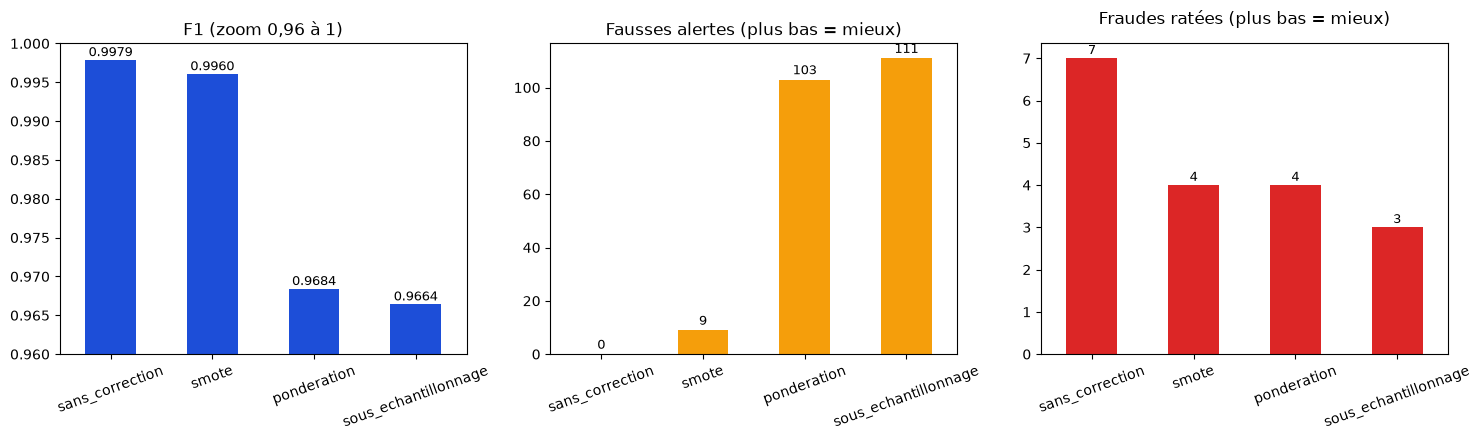

In [14]:
import matplotlib.pyplot as plt

ordre = comparaison.sort_values("f1", ascending=False)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

ordre["f1"].plot.bar(ax=axes[0], color="#1d4ed8", rot=20)
axes[0].set_ylim(0.96, 1.0)
axes[0].set_title("F1 (zoom 0,96 à 1)")
for i, v in enumerate(ordre["f1"]):
    axes[0].text(i, v + 0.0005, f"{v:.4f}", ha="center", fontsize=9)

ordre["faux_positifs"].plot.bar(ax=axes[1], color="#f59e0b", rot=20)
axes[1].set_title("Fausses alertes (plus bas = mieux)")
for i, v in enumerate(ordre["faux_positifs"]):
    axes[1].text(i, v + 2, int(v), ha="center", fontsize=9)

ordre["fraudes_ratees"].plot.bar(ax=axes[2], color="#dc2626", rot=20)
axes[2].set_title("Fraudes ratées (plus bas = mieux)", pad=14)
for i, v in enumerate(ordre["fraudes_ratees"]):
    axes[2].text(i, v + 0.1, int(v), ha="center", fontsize=9)

for ax in axes:
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

## Conclusion

*(à compléter avec tes chiffres après exécution)*

Les points à regarder dans le tableau :

- La stratégie avec le meilleur **PR-AUC** et le meilleur **F1** est celle qui équilibre le mieux fraudes détectées et fausses alertes.
- SMOTE et le sous-échantillonnage font en général **monter les faux positifs** : le modèle a vu beaucoup plus de fraudes (vraies ou inventées) que dans la réalité, donc il devient trop méfiant.
- Le sous-échantillonnage entraîne le modèle sur très peu de transactions normales, donc il connaît mal le comportement légitime.
- La pondération ne modifie pas les données : c'est pour cette raison qu'elle est retenue pour la plateforme, à condition que ses résultats soient au moins aussi bons que ceux des autres stratégies.